# Imports

In [7]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator
import os

In [8]:
class ModerationState(TypedDict):
    post_content: str
    user_reputation: str

    formatted_post : str
    content_flag : str
    result : str

# Define nodes

In [9]:
def format_post(state: ModerationState):
    formatted = f"User ({state['user_reputation']}) says: {state['post_content']}"
    return {'formatted_post': formatted}

def analyze_content(state: ModerationState):
    content = state['post_content'].lower()
    if "spam" in content or "buy now" in content:
        flag = "rejected"
    elif state['user_reputation'] == "new_user":
        flag = "review"
    else:
        flag = "approved"

    return {'content_flag': flag}


def approve_post(state: ModerationState):
    result = "Post approved and published."
    return {'result': result}

def reject_post(state: ModerationState):
    result = "Post rejected and not published."
    return {'result': result}

def flag_for_review(state: ModerationState):
    result = "Post flagged for review by moderators."
    return {'result': result}

In [10]:
def check_condition(state: ModerationState) -> Literal['approve_post', 'reject_post', 'flag_for_review']:
    # Mirrors the conditional routing based on the discriminant in the original

    if state['content_flag'] == "approved":
        return 'approve_post'
    elif state['content_flag'] == "rejected":
        return 'reject_post'
    else:
        return 'flag_for_review'

In [11]:
# create graph
graph = StateGraph(ModerationState)

# add nodes to the graph
graph.add_node('format_post', format_post)
graph.add_node('analyze_content', analyze_content)
graph.add_node('approve_post', approve_post)
graph.add_node('reject_post', reject_post)
graph.add_node('flag_for_review', flag_for_review)

# add edges to the graph
graph.add_edge(START, 'format_post')
graph.add_edge('format_post', 'analyze_content')
# conditional edges based on content analysis
graph.add_conditional_edges('analyze_content', check_condition)
graph.add_edge('approve_post', END)
graph.add_edge('reject_post', END)
graph.add_edge('flag_for_review', END)

# compile the graph into a workflow
workflow = graph.compile()

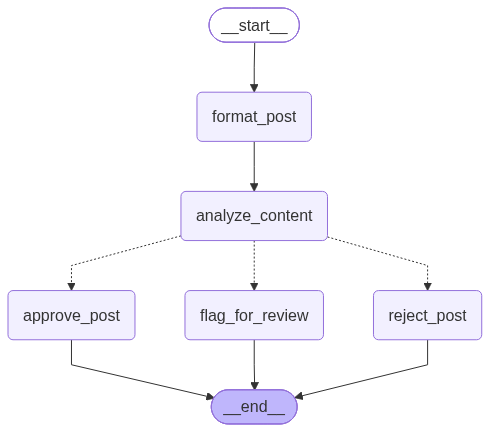

In [12]:
workflow

# test Rejected

In [13]:
initial_state = {
    'post_content': "Check out this amazing product! Buy now and get 50% off!",
    'user_reputation': "new_user"
}

final_state = workflow.invoke(initial_state)

print(final_state)

{'post_content': 'Check out this amazing product! Buy now and get 50% off!', 'user_reputation': 'new_user', 'formatted_post': 'User (new_user) says: Check out this amazing product! Buy now and get 50% off!', 'content_flag': 'rejected', 'result': 'Post rejected and not published.'}


# test Flag for review

In [14]:
initial_state = {
    'post_content': "Check out this amazing product and get 50% off!",
    'user_reputation': "new_user"
}

final_state = workflow.invoke(initial_state)

print(final_state)

{'post_content': 'Check out this amazing product and get 50% off!', 'user_reputation': 'new_user', 'formatted_post': 'User (new_user) says: Check out this amazing product and get 50% off!', 'content_flag': 'review', 'result': 'Post flagged for review by moderators.'}


# test Approved

In [17]:
initial_state = {
    'post_content': "Check out this amazing product!and get 50% off!",
    'user_reputation': "trusted_user"
}

final_state = workflow.invoke(initial_state)

print(final_state)

{'post_content': 'Check out this amazing product!and get 50% off!', 'user_reputation': 'trusted_user', 'formatted_post': 'User (trusted_user) says: Check out this amazing product!and get 50% off!', 'content_flag': 'approved', 'result': 'Post approved and published.'}
